In [5]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, transform

image = data.camera()                                   # built-in grayscale image
image = transform.resize(image, (256, 256), anti_aliasing=True)   # values scaled to 0-1

print("Image shape:", image.shape)
print("Pixel value range:", round(image.min(), 3), "to", round(image.max(), 3))

Image shape: (256, 256)
Pixel value range: 0.008 to 0.999


In [6]:
def convolve2d(img, kernel):
    """Slide the kernel over the image (stride 1, no padding) and sum the products."""
    kh, kw = kernel.shape
    h, w = img.shape
    out = np.zeros((h - kh + 1, w - kw + 1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            out[i, j] = np.sum(img[i:i + kh, j:j + kw] * kernel)
    return out

kernels = {
    "Vertical Edge (Sobel)": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]),
    "Horizontal Edge (Sobel)": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]),
    "Sharpen": np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]),
    "Blur (3x3 average)": np.ones((3, 3)) / 9,
}

feature_maps = {name: convolve2d(image, k) for name, k in kernels.items()}

In [7]:
def pool2d(img, size=2, mode="max"):
    """Non-overlapping pooling with a size x size window (stride = size)."""
    h, w = img.shape
    h, w = h - h % size, w - w % size
    blocks = img[:h, :w].reshape(h // size, size, w // size, size)
    return blocks.max(axis=(1, 3)) if mode == "max" else blocks.mean(axis=(1, 3))

edge_map = np.abs(feature_maps["Vertical Edge (Sobel)"])
max_pooled = pool2d(edge_map, 2, "max")
avg_pooled = pool2d(edge_map, 2, "avg")

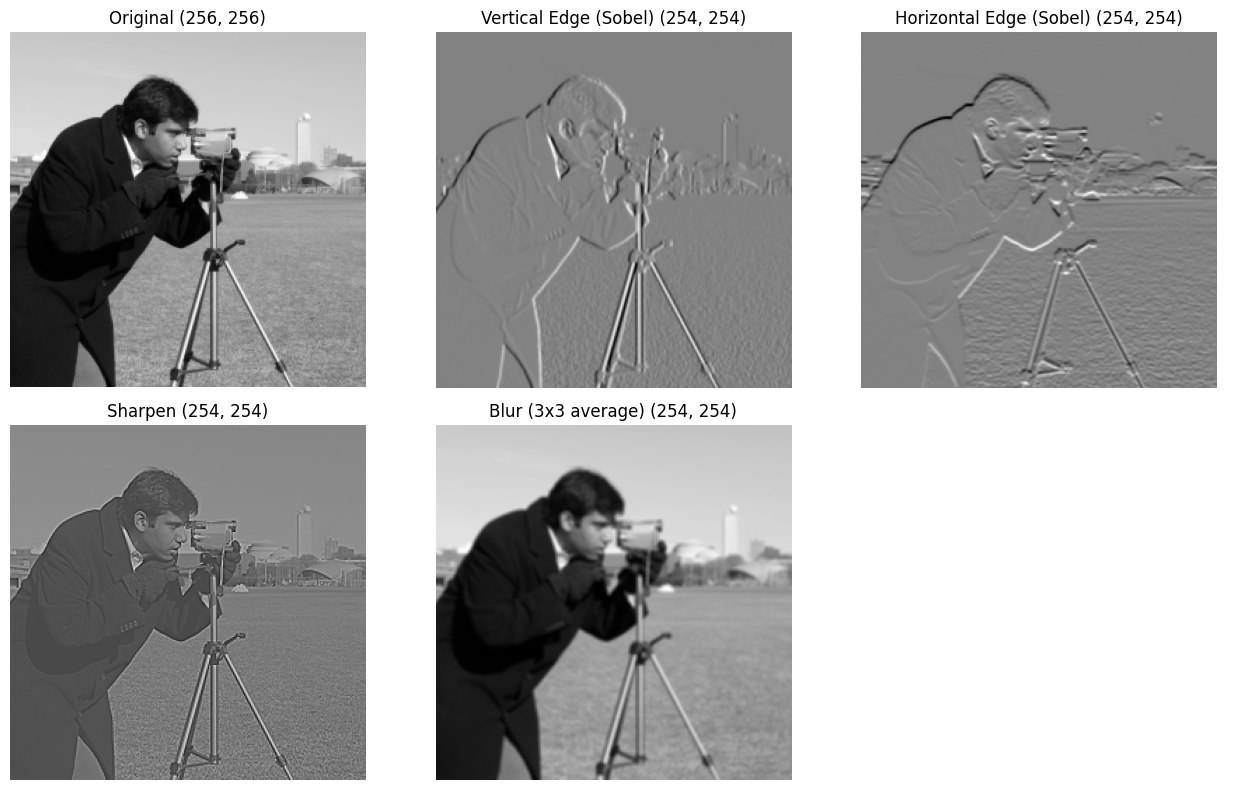

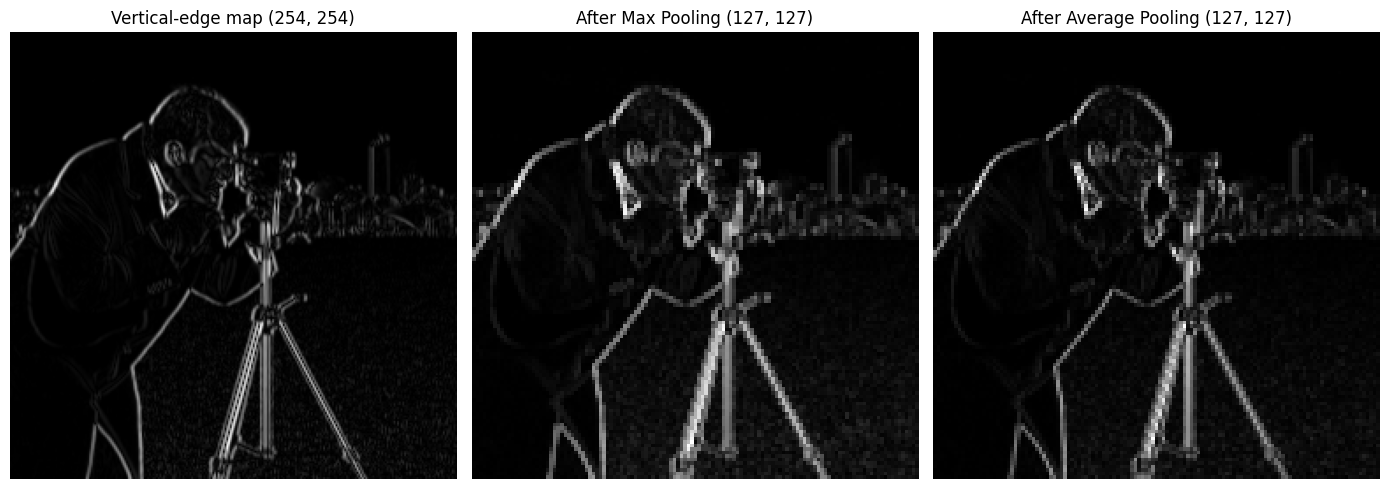

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
axes = axes.ravel()
axes[0].imshow(image, cmap="gray"); axes[0].set_title(f"Original {image.shape}")
for ax, (name, fm) in zip(axes[1:], feature_maps.items()):
    ax.imshow(fm, cmap="gray"); ax.set_title(f"{name} {fm.shape}")
axes[5].axis("off")
for ax in axes[:5]:
    ax.axis("off")
plt.tight_layout()
plt.savefig("convolution_results.png", dpi=200)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
axes[0].imshow(edge_map, cmap="gray"); axes[0].set_title(f"Vertical-edge map {edge_map.shape}")
axes[1].imshow(max_pooled, cmap="gray"); axes[1].set_title(f"After Max Pooling {max_pooled.shape}")
axes[2].imshow(avg_pooled, cmap="gray"); axes[2].set_title(f"After Average Pooling {avg_pooled.shape}")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.savefig("pooling_results.png", dpi=200)